In [1]:
# Import Libraries
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#read the data
df = pd.read_csv("./data/results.csv")
df.head()

/var/folders/7q/hg2_dwc17jng9c7169fzwrb80000gn/T/ipykernel_1558/3916281125.py:2: DtypeWarning: Columns (56: JobSatPoints_15_TEXT, 74: DatabaseHaveEntry, 92: DevEnvHaveEntry, 97: SOTagsHaveEntry, 98: SOTagsWant Entry, 105: OfficeStackWantEntry, 109: CommPlatformHaveEntr, 110: CommPlatformWantEntr, 132: SO_Actions_15_TEXT, 162: AIAgentOrchestration, 165: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("./data/results.csv")


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


In [3]:
df.shape

(49191, 172)

In [4]:
print(df.columns.tolist())
print(df.isna().mean().sort_values(ascending=False).head(30))

['ResponseId', 'MainBranch', 'Age', 'EdLevel', 'Employment', 'EmploymentAddl', 'WorkExp', 'LearnCodeChoose', 'LearnCode', 'LearnCodeAI', 'AILearnHow', 'YearsCode', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'PurchaseInfluence', 'TechEndorseIntro', 'TechEndorse_1', 'TechEndorse_2', 'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6', 'TechEndorse_7', 'TechEndorse_8', 'TechEndorse_9', 'TechEndorse_13', 'TechEndorse_13_TEXT', 'TechOppose_1', 'TechOppose_2', 'TechOppose_3', 'TechOppose_5', 'TechOppose_7', 'TechOppose_9', 'TechOppose_11', 'TechOppose_13', 'TechOppose_16', 'TechOppose_15', 'TechOppose_15_TEXT', 'Industry', 'JobSatPoints_1', 'JobSatPoints_2', 'JobSatPoints_3', 'JobSatPoints_4', 'JobSatPoints_5', 'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9', 'JobSatPoints_10', 'JobSatPoints_11', 'JobSatPoints_13', 'JobSatPoints_14', 'JobSatPoints_15', 'JobSatPoints_16', 'JobSatPoints_15_TEXT', 'AIThreat', 'NewRole', 'ToolCountWork', 'ToolCountPersona

In [5]:
cols = [
    "Country",
    "Age",
    "EdLevel",
    "Employment",
    "WorkExp",
    "YearsCode",
    "DevType",
    "OrgSize",
    "ICorPM",
    "RemoteWork",
    "Industry",
    "LanguageHaveWorkedWith",
    "DatabaseHaveWorkedWith",
    "PlatformHaveWorkedWith",
    "ConvertedCompYearly",
]
print(df[cols].isna().mean())
print(df[cols].dtypes)
print(df["ConvertedCompYearly"].notna().sum(), "people reported a salary")

Country                   0.279604
Age                       0.000000
EdLevel                   0.021183
Employment                0.017320
WorkExp                   0.128032
YearsCode                 0.125003
DevType                   0.112033
OrgSize                   0.305198
ICorPM                    0.324206
RemoteWork                0.313289
Industry                  0.316094
LanguageHaveWorkedWith    0.356163
DatabaseHaveWorkedWith    0.480596
PlatformHaveWorkedWith    0.506861
ConvertedCompYearly       0.513183
dtype: float64
Country                       str
Age                           str
EdLevel                       str
Employment                    str
WorkExp                   float64
YearsCode                 float64
DevType                       str
OrgSize                       str
ICorPM                        str
RemoteWork                    str
Industry                      str
LanguageHaveWorkedWith        str
DatabaseHaveWorkedWith        str
PlatformHaveWorked

In [6]:
raw = df.copy()

duplicates = raw.drop(columns="ResponseId").duplicated().sum()
print("duplicates : ", duplicates)

df = raw.drop_duplicates(subset=raw.columns.drop("ResponseId")).copy()
print(df.shape)
dup_rows = raw[raw.drop(columns="ResponseId").duplicated(keep=False)]
print(
    dup_rows["ConvertedCompYearly"].notna().sum(), "of the duplicate rows have a salary"
)
print(dup_rows.isna().mean(axis=1).mean().round(2), "average share of empty answers")


duplicates :  1547
(47644, 172)
0 of the duplicate rows have a salary
0.97 average share of empty answers


In [7]:
# removing the rows where comp salary is empty its critical for final prediction
before = len(df)
df = df[df["ConvertedCompYearly"].notna()]
print("removed:", before - len(df), "| remaining:", len(df))

print(df["MainBranch"].value_counts())


removed: 23697 | remaining: 23947
MainBranch
I am a developer by profession                                                                20195
I am not primarily a developer, but I write code sometimes as part of my work/studies          2187
I used to be a developer by profession, but no longer am                                        498
I work with developers or my work supports developers but am not a developer by profession      390
I am learning to code                                                                           363
I code primarily as a hobby                                                                     314
Name: count, dtype: int64


In [8]:
# keeping only the professional developer for better accuracy
before = len(df)
df = df[df["MainBranch"] == "I am a developer by profession"]
print("remove :", before - len(df), " | remaining:", len(df))

remove : 3752  | remaining: 20195


In [9]:
# dropping unemployed/retired responses - a reported salary from someone without
# a current job isn't representative of what we're trying to predict (current
# compensation based on current role, remote work, org size, etc.)
# NOTE: "Student" is kept here - the EDA compares junior salaries for
# Employed vs Student and filters Student out itself for later analyses
before = len(df)
df = df[~df["Employment"].isin(["Not employed", "Retired"])]
print("remove :", before - len(df), " | remaining:", len(df))


remove : 384  | remaining: 19811


In [10]:
# picking up only the required columns
df = df[cols].copy()
print(df.shape)

# checking for outliers
print(df["ConvertedCompYearly"].describe())
print(df["ConvertedCompYearly"].quantile([0.01, 0.05, 0.95, 0.99]))


(19811, 15)
count    1.981100e+04
mean     1.010185e+05
std      3.105159e+05
min      1.000000e+00
25%      4.200000e+04
50%      7.801100e+04
75%      1.241360e+05
max      3.355272e+07
Name: ConvertedCompYearly, dtype: float64
0.01       104.0
0.05      4042.5
0.95    232029.0
0.99    444089.7
Name: ConvertedCompYearly, dtype: float64


In [11]:
# identifying outliers country based
low_earners = df[df["ConvertedCompYearly"] < 5000]
print(len(low_earners), " People earn under $5000")
print(low_earners["Country"].value_counts().head(15))
print(low_earners["ConvertedCompYearly"].describe())

1134  People earn under $5000
Country
Ukraine                     158
India                       130
United States of America     53
Pakistan                     48
Brazil                       45
Nigeria                      37
Turkey                       32
Indonesia                    32
Poland                       27
Bangladesh                   26
Germany                      24
Kenya                        20
Egypt                        19
Nepal                        19
Argentina                    18
Name: count, dtype: int64
count    1134.000000
mean     1818.500000
std      1564.034756
min         1.000000
25%       278.750000
50%      1490.500000
75%      3190.000000
max      4993.000000
Name: ConvertedCompYearly, dtype: float64


In [13]:
# need to check and drop outliers
country_median = df.groupby("Country")["ConvertedCompYearly"].transform("median")

# flagging salaries below 10% of the median w.r.t country
too_low = df["ConvertedCompYearly"] < 0.10 * country_median
print(too_low.sum(), "salaries are below 10% of their country's median")
print(df[too_low]["Country"].value_counts().head(10))

# dropping lows and highs
high = df["ConvertedCompYearly"].quantile(0.99)
df = df[~too_low & (df["ConvertedCompYearly"] <= high)]


print(f"upper cut-off: ${high:,.0f}")
print("removed:", before - len(df), "| remaining:", len(df))
print(df["ConvertedCompYearly"].describe())

# checking for the wrong median values because of less respondants
print(df.nsmallest(15, "ConvertedCompYearly")[["Country", "ConvertedCompYearly"]])
print((df["ConvertedCompYearly"] < 1000).sum(), "people still under $1,000")

# putting in floor value to drop obvious mistakes eg 1$
before = len(df)
df = df[df["ConvertedCompYearly"] >= 1000].copy()
print("removed:", before - len(df), "| remaining:", len(df))
print(df["ConvertedCompYearly"].min())


840 salaries are below 10% of their country's median
Country
Ukraine                     121
United States of America     73
India                        50
Germany                      42
Brazil                       33
Poland                       32
Turkey                       22
Serbia                       18
Argentina                    17
Colombia                     15
Name: count, dtype: int64
upper cut-off: $444,090
removed: 1423 | remaining: 18772
count     18772.000000
mean      93815.843384
std       67580.479894
min           1.000000
25%       46406.000000
50%       81210.000000
75%      125000.000000
max      440856.000000
Name: ConvertedCompYearly, dtype: float64
                   Country  ConvertedCompYearly
34865  Antigua and Barbuda                  1.0
6680             Palestine                 78.0
35108                 Togo                354.0
5964               Namibia                367.0
4275               Nigeria                387.0
21390              Nig

In [14]:
# removing countries with less entries
counts = df["Country"].value_counts()
print("countries before: ", counts)
rare = counts[counts < 50].index
print(len(rare), "countries have fewer than 50 people")

# grouping in others category
df["Country"] = df["Country"].replace(rare, "Other")
print("countries after:", df["Country"].nunique())
print((df["Country"] == "Other").sum(), "people now in 'Other'")

print(df.isna().sum())


countries before:  Country
United States of America                                4065
Germany                                                 1702
United Kingdom of Great Britain and Northern Ireland    1235
India                                                    865
France                                                   840
                                                        ... 
Benin                                                      1
Malawi                                                     1
Belize                                                     1
Oman                                                       1
Congo, Republic of the...                                  1
Name: count, Length: 153, dtype: int64
104 countries have fewer than 50 people
countries after: 50
1126 people now in 'Other'
Country                      0
Age                          0
EdLevel                     11
Employment                   0
WorkExp                    170
YearsCode            

In [15]:
df.isna().sum()

Country                      0
Age                          0
EdLevel                     11
Employment                   0
WorkExp                    170
YearsCode                   56
DevType                      0
OrgSize                   1639
ICorPM                    1881
RemoteWork                1709
Industry                   112
LanguageHaveWorkedWith    1173
DatabaseHaveWorkedWith    3713
PlatformHaveWorkedWith    4069
ConvertedCompYearly          0
dtype: int64

In [16]:
df.drop(columns=["WorkExp"], inplace=True) 
# since it is highly correlated with YearsCode and has a lot of missing values

In [18]:
# capping impossible experience values (some respondents entered more than 50 years)
df[["YearsCode"]] = df[["YearsCode"]].clip(upper=50)

In [20]:
# standardising the different "didn't answer" labels into a single Unknown label
df = df.replace(
    {
        "I don’t know": "Unknown",  # curly ’ as in the survey
        "Prefer not to say": "Unknown",
        "I prefer not to say": "Unknown",
    }
)


In [35]:
# filling the rest where missing too many to drop
fill_cols = ["EdLevel", "OrgSize", "RemoteWork", "ICorPM", "Industry", "LanguageHaveWorkedWith", "DatabaseHaveWorkedWith", "PlatformHaveWorkedWith"]
df[fill_cols] = df[fill_cols].fillna("Unknown")

print(df.isna().sum().sum())


56


In [36]:
df.isna().sum()

Country                    0
Age                        0
EdLevel                    0
Employment                 0
YearsCode                 56
DevType                    0
OrgSize                    0
ICorPM                     0
RemoteWork                 0
Industry                   0
LanguageHaveWorkedWith     0
DatabaseHaveWorkedWith     0
PlatformHaveWorkedWith     0
ConvertedCompYearly        0
dtype: int64

In [55]:
dev_map = {
    # Software development
    "Developer, full-stack": "Full-stack",
    "Developer, back-end": "Back-end",
    "Developer, front-end": "Front-end",
    "Developer, mobile": "Mobile",
    "Developer, desktop or enterprise applications": "Desktop/Enterprise",
    "Developer, embedded applications or devices": "Embedded",
    "Developer, game or graphics": "Game/Graphics",
    "Architect, software or solutions": "Architecture",

    # Management and leadership
    "Engineering manager": "Management",
    "Senior executive (C-suite, VP, etc.)": "Management",
    "Founder, technology or otherwise": "Management",
    "Project manager": "Management",
    "Product manager": "Management",

    # Data, AI and analytics
    "Data engineer": "Data/AI/Analytics",
    "AI/ML engineer": "Data/AI/Analytics",
    "Data scientist": "Data/AI/Analytics",
    "Applied scientist": "Data/AI/Analytics",
    "Developer, AI apps or physical AI": "Data/AI/Analytics",
    "Data or business analyst": "Data/AI/Analytics",

    # Infrastructure and operations
    "DevOps engineer or professional": "Infrastructure/Operations",
    "Cloud infrastructure engineer": "Infrastructure/Operations",
    "System administrator": "Infrastructure/Operations",
    "Database administrator or engineer": "Infrastructure/Operations",

    # Security
    "Cybersecurity or InfoSec professional": "Security",

    # Quality assurance and support
    "Developer, QA or test": "QA/Testing",
    "Support engineer or analyst": "IT Support",

    # Academic and other
    "Academic researcher": "Academic/Research",
    "Student": "Student",
    "Retired": "Retired",
    "Other (please specify):": "Other",
    "Financial analyst or engineer": "Other",
    "UX, Research Ops or UI design professional": "Other",
}

df["DevType_grp"] = df["DevType"].map(dev_map).fillna("Other")

print(df["DevType_grp"].value_counts())


DevType_grp
Full-stack                   6810
Back-end                     3581
Architecture                 1302
Data/AI/Analytics            1112
Desktop/Enterprise           1015
Front-end                     969
Management                    864
Infrastructure/Operations     743
Embedded                      694
Mobile                        686
Other                         326
Game/Graphics                 174
Academic/Research             163
QA/Testing                    107
Student                        87
Security                       72
IT Support                     29
Retired                         2
Name: count, dtype: int64


In [57]:
df["EdLevel"].value_counts()

EdLevel
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                                          8571
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                                       5505
Some college/university study without earning a degree                                2175
Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)     830
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                                         819
Associate degree (A.A., A.S., etc.)                                                    615
Other (please specify):                                                                138
Primary/elementary school                                                               72
Unknown                                                                                 11
Name: count, dtype: int64

In [ ]:
edu_level = {
    # Bachelor's degrees
    "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": "Bachelor",
    # Master's degrees
    "Master’s degree (M.A., M.S., M.Eng., MBA, etc.)": "Master",
    # Doctoral degrees
    "Professional degree (JD, MD, Ph.D, Ed.D, etc.)": "Professional",
    #no higher degree
    "Some college/university study without earning a degree": "Some college without degree",
    "Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)": "Secondary school",
    "Associate degree (A.A., A.S., etc.) ": "Associate",
    "Primary/elementary school": "Primary school",
    "Unknown": "Unknown",
    
    # Other degrees
    "Other (please specify):": "Other"
}
    "Developer, game or graphics": "Game/Graphics",
    "Architect, software or solutions": "Architecture",

    # Management and leadership
    "Engineering manager": "Management",
    "Senior executive (C-suite, VP, etc.)": "Management",
    "Founder, technology or otherwise": "Management",
    "Project manager": "Management",
    "Product manager": "Management",

    # Data, AI and analytics
    "Data engineer": "Data/AI/Analytics",
    "AI/ML engineer": "Data/AI/Analytics",
    "Data scientist": "Data/AI/Analytics",
    "Applied scientist": "Data/AI/Analytics",
    "Developer, AI apps or physical AI": "Data/AI/Analytics",
    "Data or business analyst": "Data/AI/Analytics",

    # Infrastructure and operations
    "DevOps engineer or professional": "Infrastructure/Operations",
    "Cloud infrastructure engineer": "Infrastructure/Operations",
    "System administrator": "Infrastructure/Operations",
    "Database administrator or engineer": "Infrastructure/Operations",

    # Security
    "Cybersecurity or InfoSec professional": "Security",

    # Quality assurance and support
    "Developer, QA or test": "QA/Testing",
    "Support engineer or analyst": "IT Support",

    # Academic and other
    "Academic researcher": "Academic/Research",
    "Student": "Student",
    "Retired": "Retired",
    "Other (please specify):": "Other",
    "Financial analyst or engineer": "Other",
    "UX, Research Ops or UI design professional": "Other",
}

df["DevType_grp"] = df["DevType"].map(dev_map).fillna("Other")

print(df["DevType_grp"].value_counts())


### Imputing Years of Code

In [42]:
df[df["YearsCode"].isna()].head(5)

,Country,Age,EdLevel,Employment,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,LanguageHaveWorkedWith,DatabaseHaveWorkedWith,PlatformHaveWorkedWith,ConvertedCompYearly
3028,Taiwan,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,NaN,"Developer, mobile","10,000 or more employees",Individual contributor,"Hybrid (some remote, leans heavy to in-person)",Software Development,Unknown,Unknown,Unknown,67772.0
3323,United States of America,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,NaN,AI/ML engineer,"1,000 to 4,999 employees",Individual contributor,In-person,"Internet, Telecomm or Information Services",JavaScript;Python,SQLite,Amazon Web Services (AWS);Google Cloud;Kuberne...,350000.0
3437,France,35-44 years old,Some college/university study without earning ...,"Independent contractor, freelancer, or self-em...",NaN,Engineering manager,Less than 20 employees,People manager,"Hybrid (some in-person, leans heavy to flexibi...",Software Development,Unknown,PostgreSQL;Redis;SQLite,Amazon Web Services (AWS);Composer;Docker;Fire...,58007.0
3619,India,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,NaN,"Developer, front-end","10,000 or more employees",Individual contributor,Remote,Software Development,C#;HTML/CSS;JavaScript;TypeScript,Unknown,Homebrew;Microsoft Azure;MSBuild;npm;NuGet;Ver...,75556.0
4194,United States of America,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,NaN,"Developer, full-stack",100 to 499 employees,Individual contributor,In-person,Software Development,Bash/Shell (all shells);Go;HTML/CSS;JavaScript...,BigQuery;Cassandra;MongoDB;PostgreSQL;Redis;SQ...,Amazon Web Services (AWS);Datadog;Digital Ocea...,185000.0


In [40]:
#df[df["YearsCode"].isna()]

print(df[["Age", "EdLevel", "Country", "YearsCode"]].isna().sum())

print(df["YearsCode"].value_counts(dropna=False).head(20))

Age           0
EdLevel       0
Country       0
YearsCode    56
dtype: int64
YearsCode
10.0    1345
20.0    1283
15.0    1280
12.0     936
25.0     902
8.0      871
30.0     814
7.0      673
6.0      670
9.0      668
13.0     655
14.0     590
5.0      583
18.0     570
16.0     567
11.0     525
17.0     470
40.0     418
35.0     408
4.0      375
Name: count, dtype: int64


In [46]:
def impute_years_code(df, min_matches=5):
    df = df.copy()

    # Preserve the original values
    df["YearsCode_imputed"] = df["YearsCode"]

    # Use only respondents who reported coding experience as donors
    donors = df[df["YearsCode"].notna()]

    for idx in df.index[df["YearsCode"].isna()]:
        person = df.loc[idx]

        # 1. Same country + age group + education
        matches = donors[
            (donors["Country"] == person["Country"]) &
            (donors["Age"] == person["Age"]) &
            (donors["EdLevel"] == person["EdLevel"])
        ]

        # 2. Same country + age group
        if len(matches) < min_matches:
            matches = donors[
                (donors["Country"] == person["Country"]) &
                (donors["Age"] == person["Age"])
            ]

        # 3. Same country + education
        if len(matches) < min_matches:
            matches = donors[
                (donors["Country"] == person["Country"]) &
                (donors["EdLevel"] == person["EdLevel"])
            ]

        # 4. Same country
        if len(matches) < min_matches:
            matches = donors[
                donors["Country"] == person["Country"]
            ]

        # Impute if enough donors are available
        if len(matches) >= min_matches:
            df.loc[idx, "YearsCode_imputed"] = (
                matches["YearsCode"].median()
            )

        # Otherwise, leave missing for now

    return df


df = impute_years_code(df)

print("Missing before:", df["YearsCode"].isna().sum())
print("Missing after:", df["YearsCode_imputed"].isna().sum())

Missing before: 56
Missing after: 0


In [50]:
mask = (
    (df["Country"] == "India") &
    (df["Age"] == "25-34 years old") &
    (df["EdLevel"] == "Bachelor’s degree (B.A., B.S., B.Eng., etc.)") &
    (df["YearsCode"].isna())
)

df.loc[mask, [
    "Country", "Age", "EdLevel",
    "YearsCode", "YearsCode_imputed"
]]

,Country,Age,EdLevel,YearsCode,YearsCode_imputed
3619,India,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",NaN,10.0
37821,India,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",NaN,10.0


In [52]:
df.groupby("Age", observed=True)["YearsCode"].agg(
    ["count", "median"]
)

,count,median
Age,,
18-24 years old,1774,7.0
25-34 years old,7047,12.0
35-44 years old,6087,20.0
45-54 years old,2600,30.0
55-64 years old,991,40.0
65 years or older,168,45.0
Unknown,13,15.0


In [53]:
df["YearsCode_missing"] = df["YearsCode"].isna()

df.groupby("YearsCode_missing", dropna=False)["ConvertedCompYearly"].agg(
    ["count", "median", "mean"]
)

,count,median,mean
YearsCode_missing,,,
False,18680,81210.0,94011.807602
True,56,69850.5,88319.803571


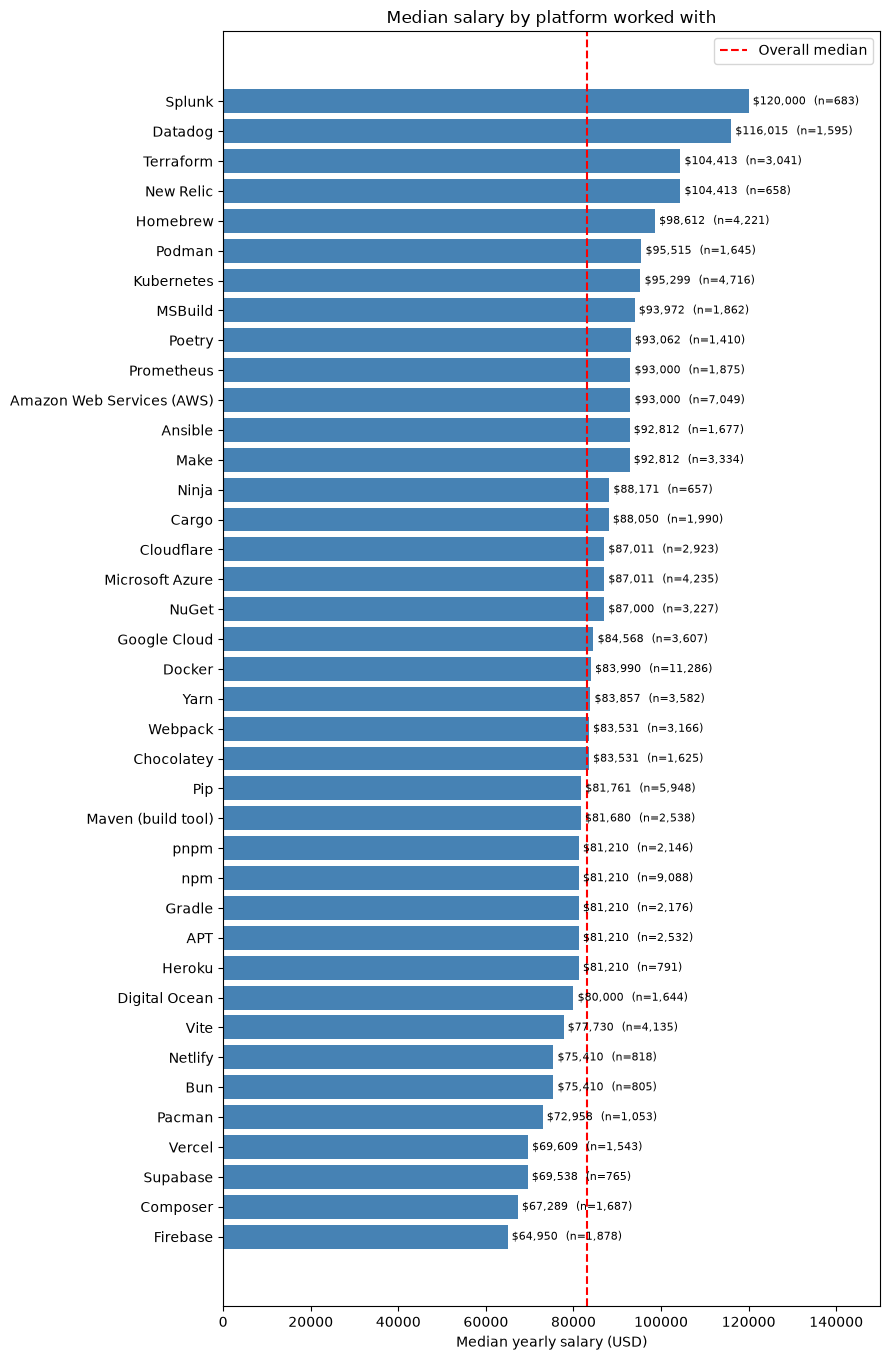

In [33]:
d = df[['PlatformHaveWorkedWith', 'ConvertedCompYearly']].dropna()
ex = (d.assign(Platform=d['PlatformHaveWorkedWith'].str.split(';'))
        .explode('Platform'))
ex['Platform'] = ex['Platform'].str.strip()

stats = (ex.groupby('Platform')["ConvertedCompYearly"]
           .agg(n='count', median='median')
           .query('n >= 300')                # drop rare platforms
           .sort_values('median'))

fig, ax = plt.subplots(figsize=(9, 0.3 * len(stats) + 2))
bars = ax.barh(stats.index, stats['median'], color='steelblue')
ax.axvline(d["ConvertedCompYearly"].median(), color='red', ls='--', label='Overall median')
labels = [f"${m:,.0f}  (n={n:,})" for m, n in zip(stats['median'], stats['n'])]
ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
ax.set_xlim(0, stats['median'].max() * 1.25)   # leave room so labels aren't clipped
ax.set_xlabel('Median yearly salary (USD)')
ax.set_title('Median salary by platform worked with')
ax.legend()
plt.tight_layout()
plt.show()

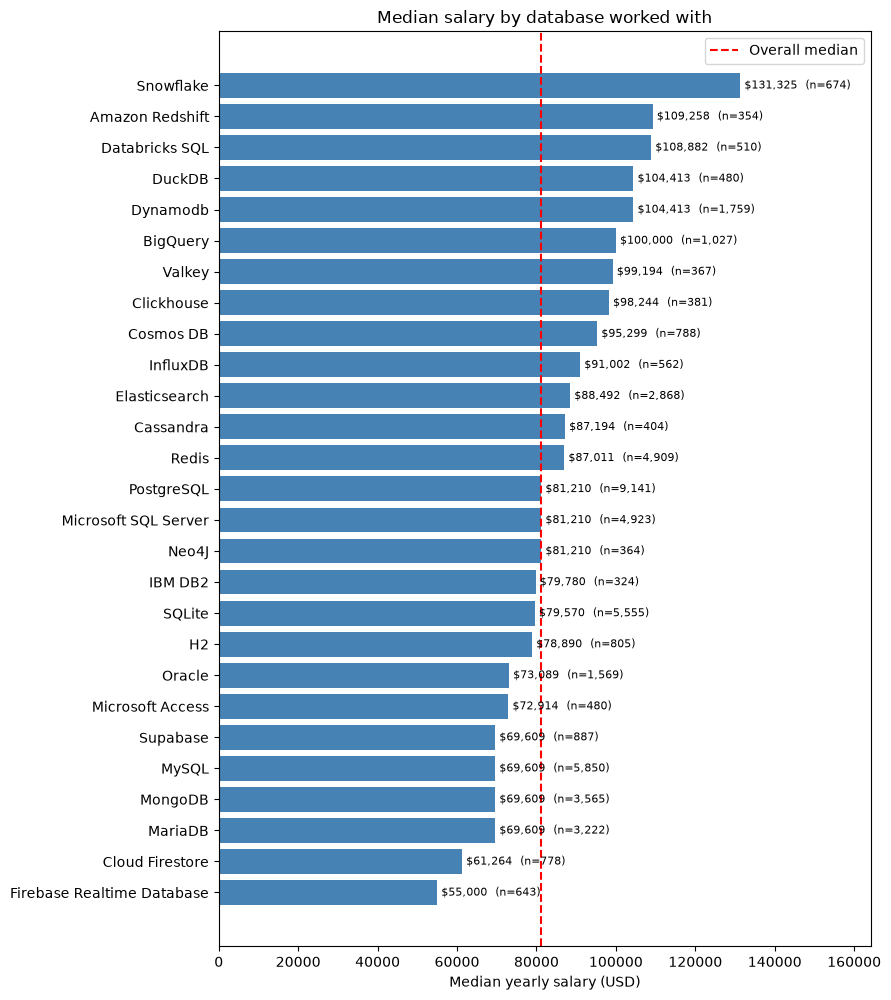

In [34]:
d = df[['DatabaseHaveWorkedWith', 'ConvertedCompYearly']].dropna()
ex = (d.assign(Database=d['DatabaseHaveWorkedWith'].str.split(';'))
        .explode('Database'))
ex['Database'] = ex['Database'].str.strip()

stats = (ex.groupby('Database')["ConvertedCompYearly"]
           .agg(n='count', median='median')
           .query('n >= 300')                # drop rare platforms
           .sort_values('median'))

fig, ax = plt.subplots(figsize=(9, 0.3 * len(stats) + 2))
bars = ax.barh(stats.index, stats['median'], color='steelblue')
ax.axvline(d["ConvertedCompYearly"].median(), color='red', ls='--', label='Overall median')
labels = [f"${m:,.0f}  (n={n:,})" for m, n in zip(stats['median'], stats['n'])]
ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
ax.set_xlim(0, stats['median'].max() * 1.25)   # leave room so labels aren't clipped
ax.set_xlabel('Median yearly salary (USD)')
ax.set_title('Median salary by database worked with')
ax.legend()
plt.tight_layout()
plt.show()

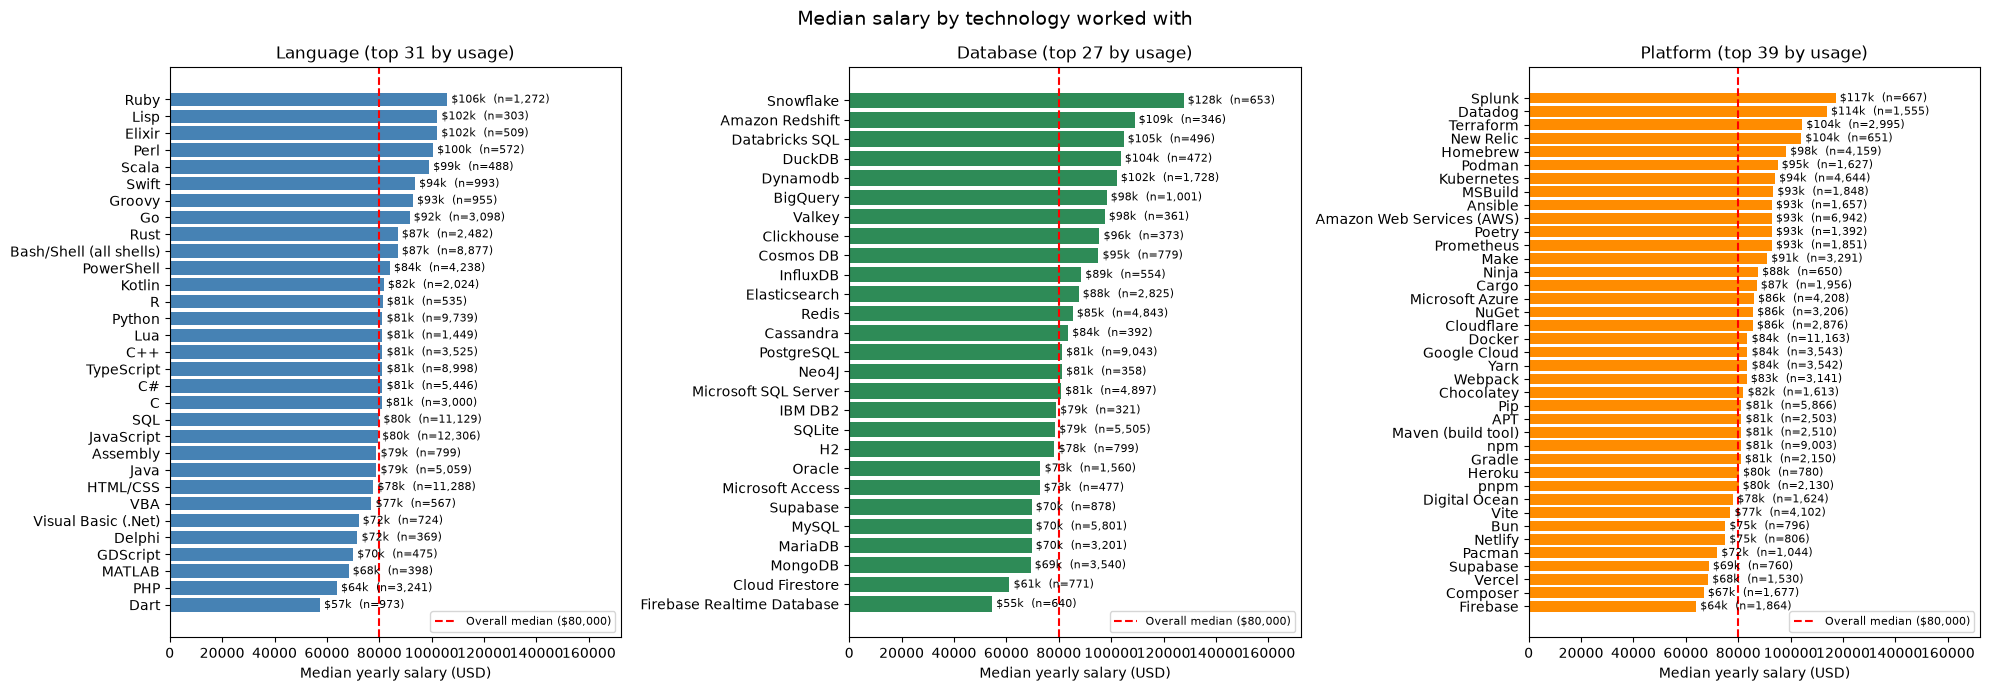

                               n    median
item                                      
Docker                     11163   83531.0
npm                         9003   81210.0
Amazon Web Services (AWS)   6942   92812.0
Pip                         5866   81210.0
Kubernetes                  4644   94000.0
Microsoft Azure             4208   85967.0
Homebrew                    4159   98244.0
Vite                        4102   76982.5
Google Cloud                3543   83531.0
Yarn                        3542   83531.0
Make                        3291   91018.0
NuGet                       3206   85651.5
Webpack                     3141   83212.0
Terraform                   2995  104413.0
Cloudflare                  2876   85535.0
Maven (build tool)          2510   81210.0
APT                         2503   81210.0
Gradle                      2150   80935.5
pnpm                        2130   80104.5
Cargo                       1956   87011.0
              n    median
item                     
Sp

In [46]:
t = 'ConvertedCompYearly'
groups = {
    'Language': 'LanguageHaveWorkedWith',
    'Database': 'DatabaseHaveWorkedWith',
    'Platform': 'PlatformHaveWorkedWith',
}
colors = {'Language': 'steelblue', 'Database': 'seagreen', 'Platform': 'darkorange'}

# Same salary filter for all three panels
base = df[df[t].notna()]
base = base[base[t] < base[t].quantile(0.99)]
overall = base[t].median()

def median_by_item(col, min_n=300, top=None):
    d = base[[col, t]].dropna()
    ex = d.assign(item=d[col].str.split(';')).explode('item')
    ex['item'] = ex['item'].str.strip()
    s = (ex.groupby('item')[t]
           .agg(n='count', median='median')
           .query('n >= @min_n'))
    if top is not None:
        s = s.nlargest(top, 'n')          # only cap when a number is given
    return s.sort_values('median')

fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharex=True)

for ax, (name, col) in zip(axes, groups.items()):
    s = median_by_item(col, min_n=300, top=None)
    bars = ax.barh(s.index, s['median'], color=colors[name])
    ax.axvline(overall, color='red', ls='--', label=f'Overall median (${overall:,.0f})')

    labels = [f"${m/1000:,.0f}k  (n={n:,})" for m, n in zip(s['median'], s['n'])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

    ax.set_title(f'{name} (top {len(s)} by usage)')
    ax.set_xlabel('Median yearly salary (USD)')
    ax.legend(loc='lower right', fontsize=8)

axes[0].set_xlim(0, base[t].quantile(0.99) * 0.0 + max(
    median_by_item(c)['median'].max() for c in groups.values()) * 1.35)

fig.suptitle('Median salary by technology worked with', fontsize=14)
plt.tight_layout()
plt.show()

s_all = median_by_item(col, min_n=300, top=None)
print(s_all.sort_values('n', ascending=False).head(20))   # Splunk's rank by usage
print(s_all.loc[['Splunk', 'Terraform']])